# Cagayan de Oro tourist driving tour using discrete PSO

Eight locations selected from the [LakbayPinas guide](https://lakbaypinas.com/19-must-visit-cagayan-de-oro-tourist-spots-travel/), with Plaza Divisoria as start and finish. Minimize the sum of saved OSRM recommended car-route distances. Directed costs preserve route asymmetry.

This notebook imports the shared solver and CSVs. There are no independent hard-coded coordinates, distance matrices or PSO implementations. The committed source snapshot runs offline. Map-derived access points are not verified parking/entrance locations; sightseeing, on-site walking, opening hours and live traffic are outside the model.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "cdo_tsp_pso_solver.py").exists():
    ROOT = ROOT / "Particle-Swarm-Optimization"
if not (ROOT / "cdo_tsp_pso_solver.py").exists():
    raise RuntimeError("Open this notebook from the repository directory or its parent.")
sys.path.insert(0, str(ROOT))
import cdo_tsp_pso_solver as solver
from scripts.build_dataset import build
from cdo_tsp_plots import generate_visualizations
import tempfile
import json

# Check reproducible derivation without overwriting the repository inputs.
with tempfile.TemporaryDirectory() as temp:
    audit = build(Path(temp))
    for name in ["cdo_tsp_dataset.csv", "cdo_tsp_locations.csv"]:
        assert (Path(temp) / name).read_bytes() == (ROOT / name).read_bytes(), name
print(json.dumps(audit, indent=2))


{
  "locations": 8,
  "ordered_pairs_including_diagonal": 64,
  "independently_requested_routes": 56,
  "max_route_table_difference_m": 0.0,
  "max_snap_distance_m": 49.244,
  "osm_base_timestamp": "2026-10-14T03:58:17Z",
  "acquired_from_utc": "2026-10-14T03:59:57.102255+00:00",
  "acquired_to_utc": "2026-10-14T04:08:22.881088+00:00",
  "osrm_data_version": "Not supplied by public server",
  "attribution": "\u00a9 OpenStreetMap contributors; ODbL 1.0; https://www.openstreetmap.org/copyright",
  "cost_definition": "Lengths of OSRM recommended driving routes; not shortest-distance road paths or live-traffic measurements",
  "access_status": "Map-derived routing points; no field verification of entrances, parking, permits or current opening"
}


## 1. Locations and directed travel costs

`Latitude`/`Longitude` locate each attraction. `Route_Latitude`/`Route_Longitude` identify the snapped car-network point used in the costs. `Distance_m` is in metres; internal costs are integer decimetres for exact arithmetic. Display rounding below does not change optimization.


In [2]:
locations, matrix = solver.load_dataset(ROOT)
for p in locations:
    print(f"{p['Node_ID']}: {p['Location_Name']}")
    print(f"  {p['Access_Note']}")
print("\nDirected distances (km):")
print("       " + " ".join(f"{p['Node_ID']:>7}" for p in locations))
for p, row in zip(locations, matrix):
    print(p["Node_ID"] + " " + " ".join(f"{v/10000:7.4f}" for v in row))


V0: Plaza Divisoria
  Meeting point on R. N. Abejuela Street; plaza walking excluded.
V1: Gaston Park
  Nearby car-network point; walking into the park excluded.
V2: St. Augustine Metropolitan Cathedral
  Designated road node 1911435359 on Gaston Circle; worship-site access not assumed.
V3: Museo de Oro
  Designated road node 7655144218 on Corrales Avenue outside the campus; museum/campus permission and walking excluded.
V4: Vicente de Lara Park
  Nearby car-network point on Don Apolinar Velez Street; park walking excluded.
V5: High Ridge
  OSRM road point near mapped restaurant; visitor access and parking assumed.
V6: Amaya View
  OSRM road point near mapped attraction centre; visitor access and parking assumed.
V7: Gardens of Malasag Eco-Tourism Village
  OSRM road point near mapped recreation grounds; visitor access and parking assumed.

Directed distances (km):
            V0      V1      V2      V3      V4      V5      V6      V7
V0  0.0000  0.6335  0.7440  0.3565  1.4477  4.4927 

## 2. Exact benchmark, nearest neighbor, and PSO

The exact solver evaluates 7! = 5,040 depot-fixed orders, including both directions. PSO uses 40 particles, 120 fully evaluated updates, swap-retention probability 0.5, personal/social alignment probabilities 0.8, and exploratory-swap probability 0.2. Iteration 0 is the initial population. It does not receive the exact solution.

The seeded demonstration and 30 additional runs (seeds 0–29) use the same saved matrix. Results here are written under `results/notebook_run/` so they do not overwrite the report's canonical run.


In [3]:
output = ROOT / "results" / "notebook_run"
summary, locations, matrix, history = solver.run_experiment(ROOT, output, seed=123, runs=30)
print(json.dumps(summary, indent=2))


{
  "problem": "Eight-stop CDO tourist driving tour",
  "objective": "Minimize the sum of stored OSRM recommended driving-route distances",
  "input_sha256": {
    "cdo_tsp_dataset.csv": "0dd9e7cae1ef0acee284aaba8094bf437d7f64a9878a0c37d9fa210ed9600a76",
    "cdo_tsp_locations.csv": "647c01c579f6967eb011c271bfcc8be305d1e75177ffcfb9736d87ab96aa5f7a"
  },
  "python_version": "3.13.13",
  "parameters": {
    "num_particles": 40,
    "max_iterations": 120,
    "w": 0.5,
    "c1": 0.8,
    "c2": 0.8,
    "mutation": 0.2,
    "seed": 123
  },
  "pso_tour": [
    0,
    3,
    4,
    7,
    6,
    5,
    2,
    1
  ],
  "pso_distance_m": 36473.9,
  "exact_tour": [
    0,
    3,
    1,
    2,
    5,
    6,
    7,
    4
  ],
  "exact_distance_m": 35953.7,
  "exact_tours_evaluated": 5040,
  "nearest_neighbor_tour": [
    0,
    3,
    1,
    2,
    4,
    5,
    6,
    7
  ],
  "nearest_neighbor_distance_m": 38499.3,
  "optimality_gap_percent": 1.4468608237816971,
  "matches_exact": false,
  "fi

## 3. Closed-tour audit

Each required stop occurs once in the visiting order. Connecting roads can be reused or pass near another attraction; a scheduled visit is distinct from driving past it.


In [4]:
tour = summary["pso_tour"]
assert solver.verify_tour(tour, matrix) == round(summary["pso_distance_m"] * 10)
total = 0
for k, u in enumerate(tour):
    v = tour[(k + 1) % len(tour)]
    total += matrix[u][v]
    print(f"{k+1}: V{u} -> V{v}: {matrix[u][v] / 10000:.4f} km")
print(f"Total: {total / 10000:.4f} km")
print(f"Exact optimum: {summary['exact_distance_m'] / 1000:.4f} km")
print(f"Gap: {summary['optimality_gap_percent']:.4f}%")


1: V0 -> V3: 0.3565 km
2: V3 -> V4: 1.3014 km
3: V4 -> V7: 8.7112 km
4: V7 -> V6: 13.5305 km
5: V6 -> V5: 7.3656 km
6: V5 -> V2: 4.6876 km
7: V2 -> V1: 0.1585 km
8: V1 -> V0: 0.3626 km
Total: 36.4739 km
Exact optimum: 35.9537 km
Gap: 1.4469%


## 4. Figures from this run

The map uses saved road polylines, not straight lines between attraction centres. Optimality labels are conditional on the exact comparison. © OpenStreetMap contributors, ODbL; routing by OSRM.


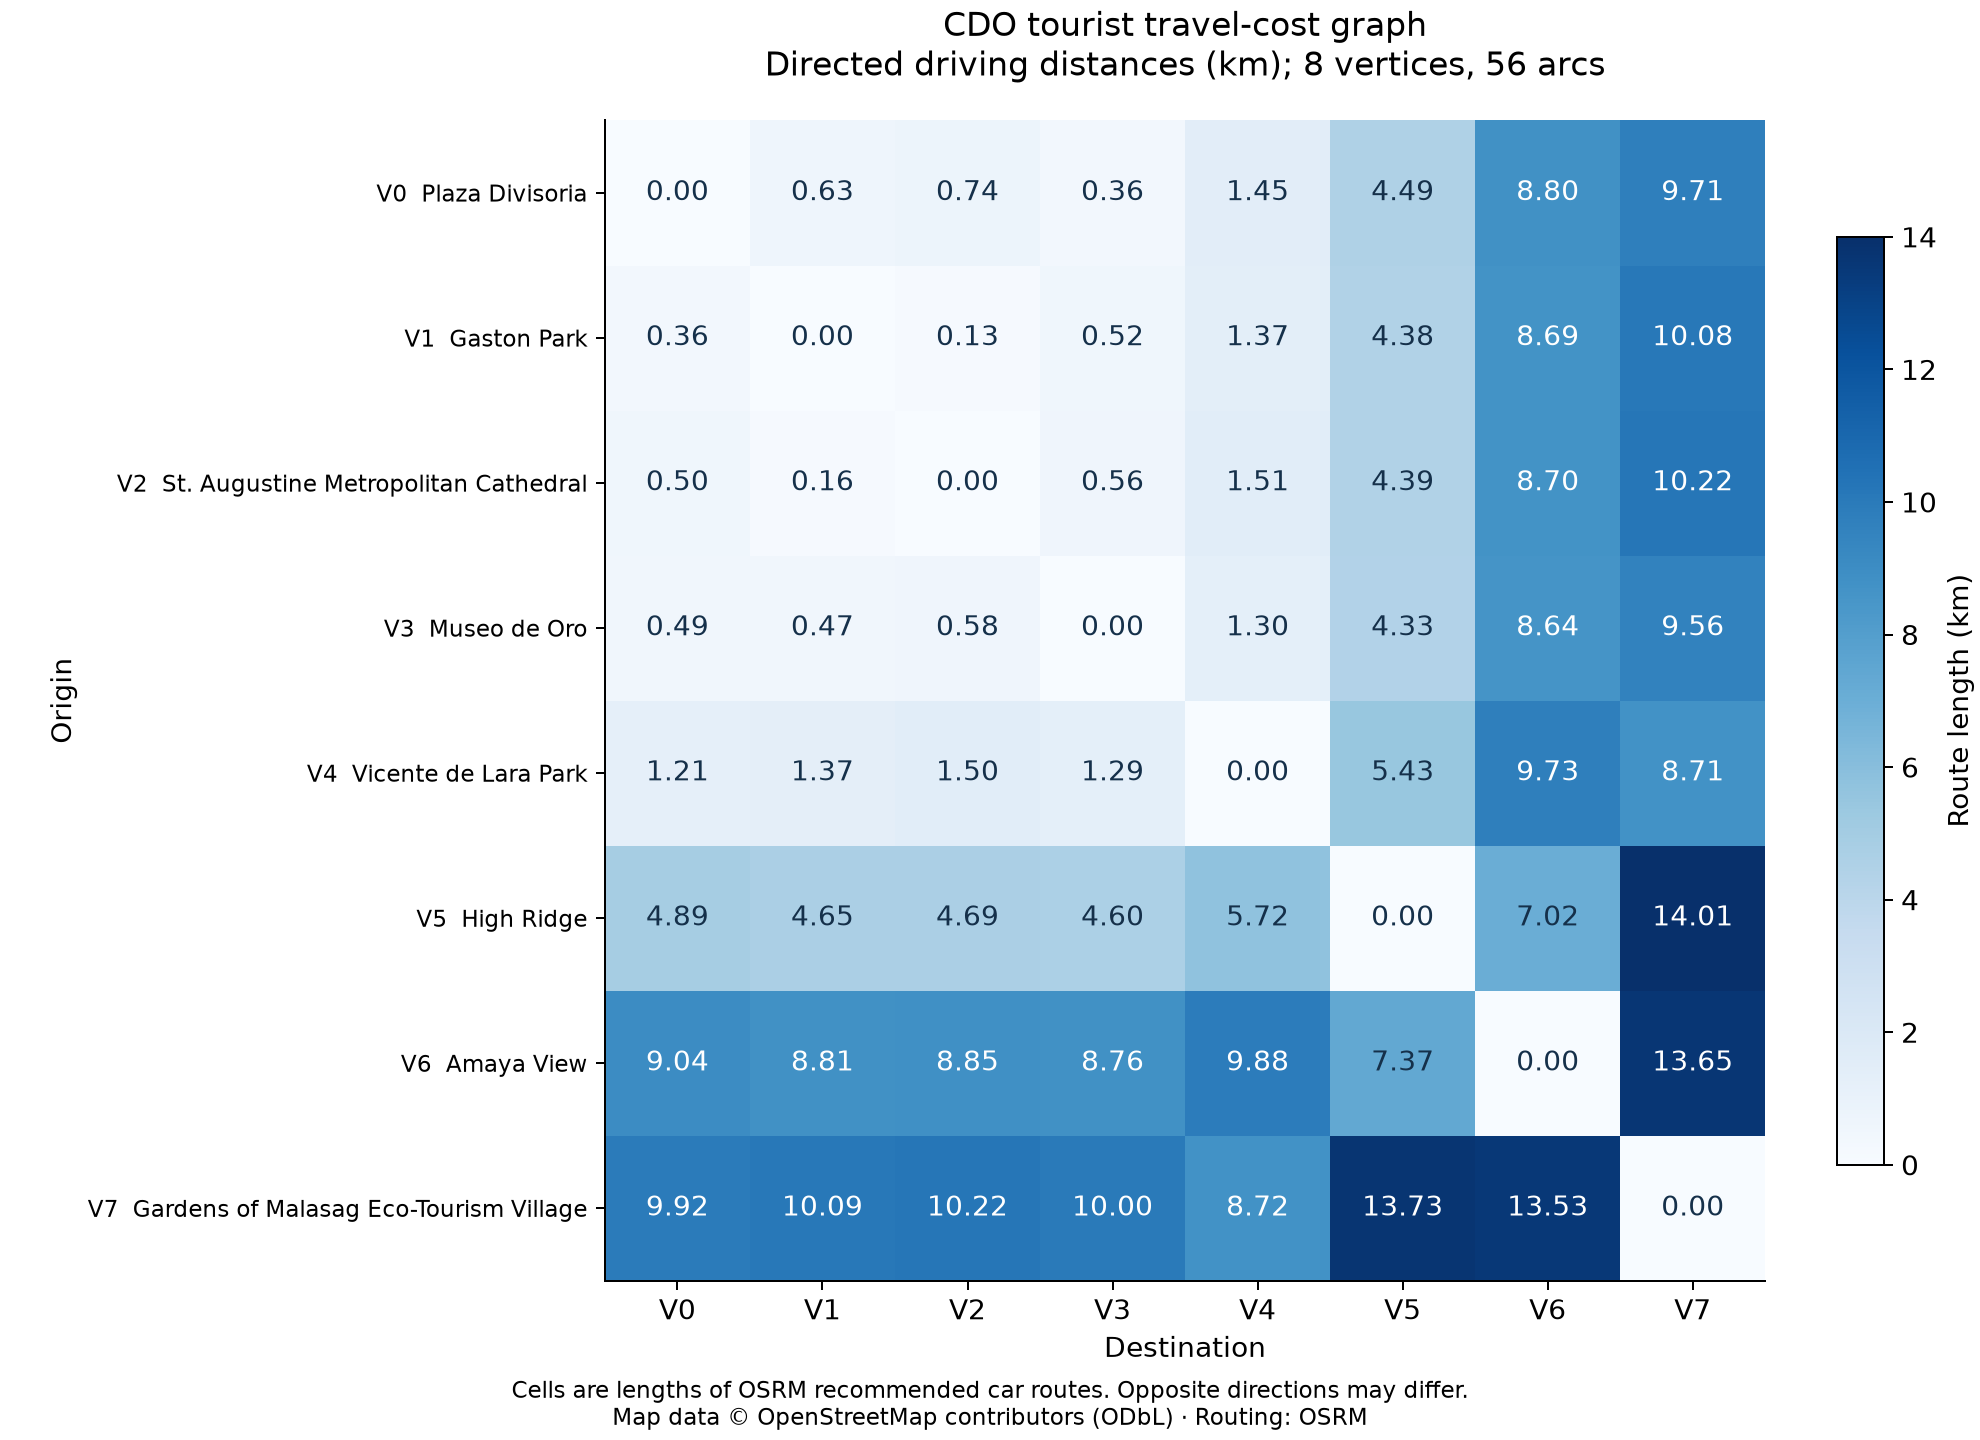

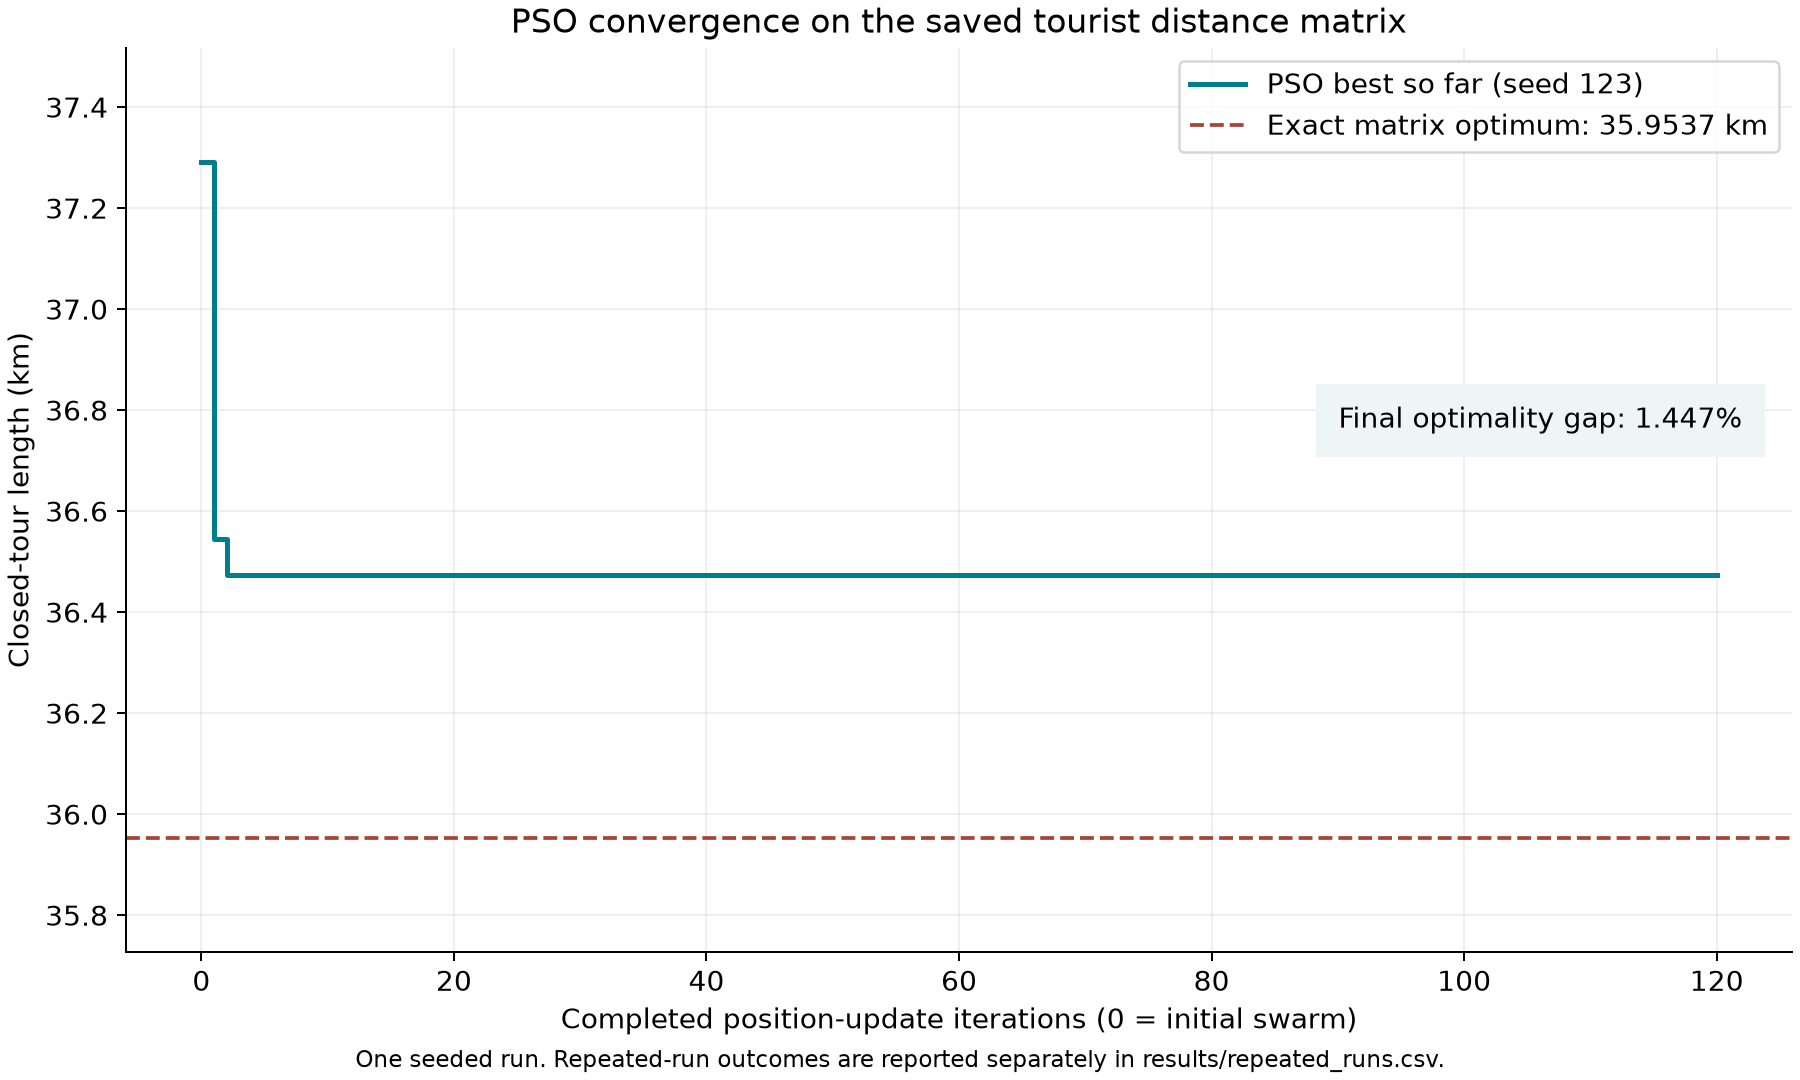

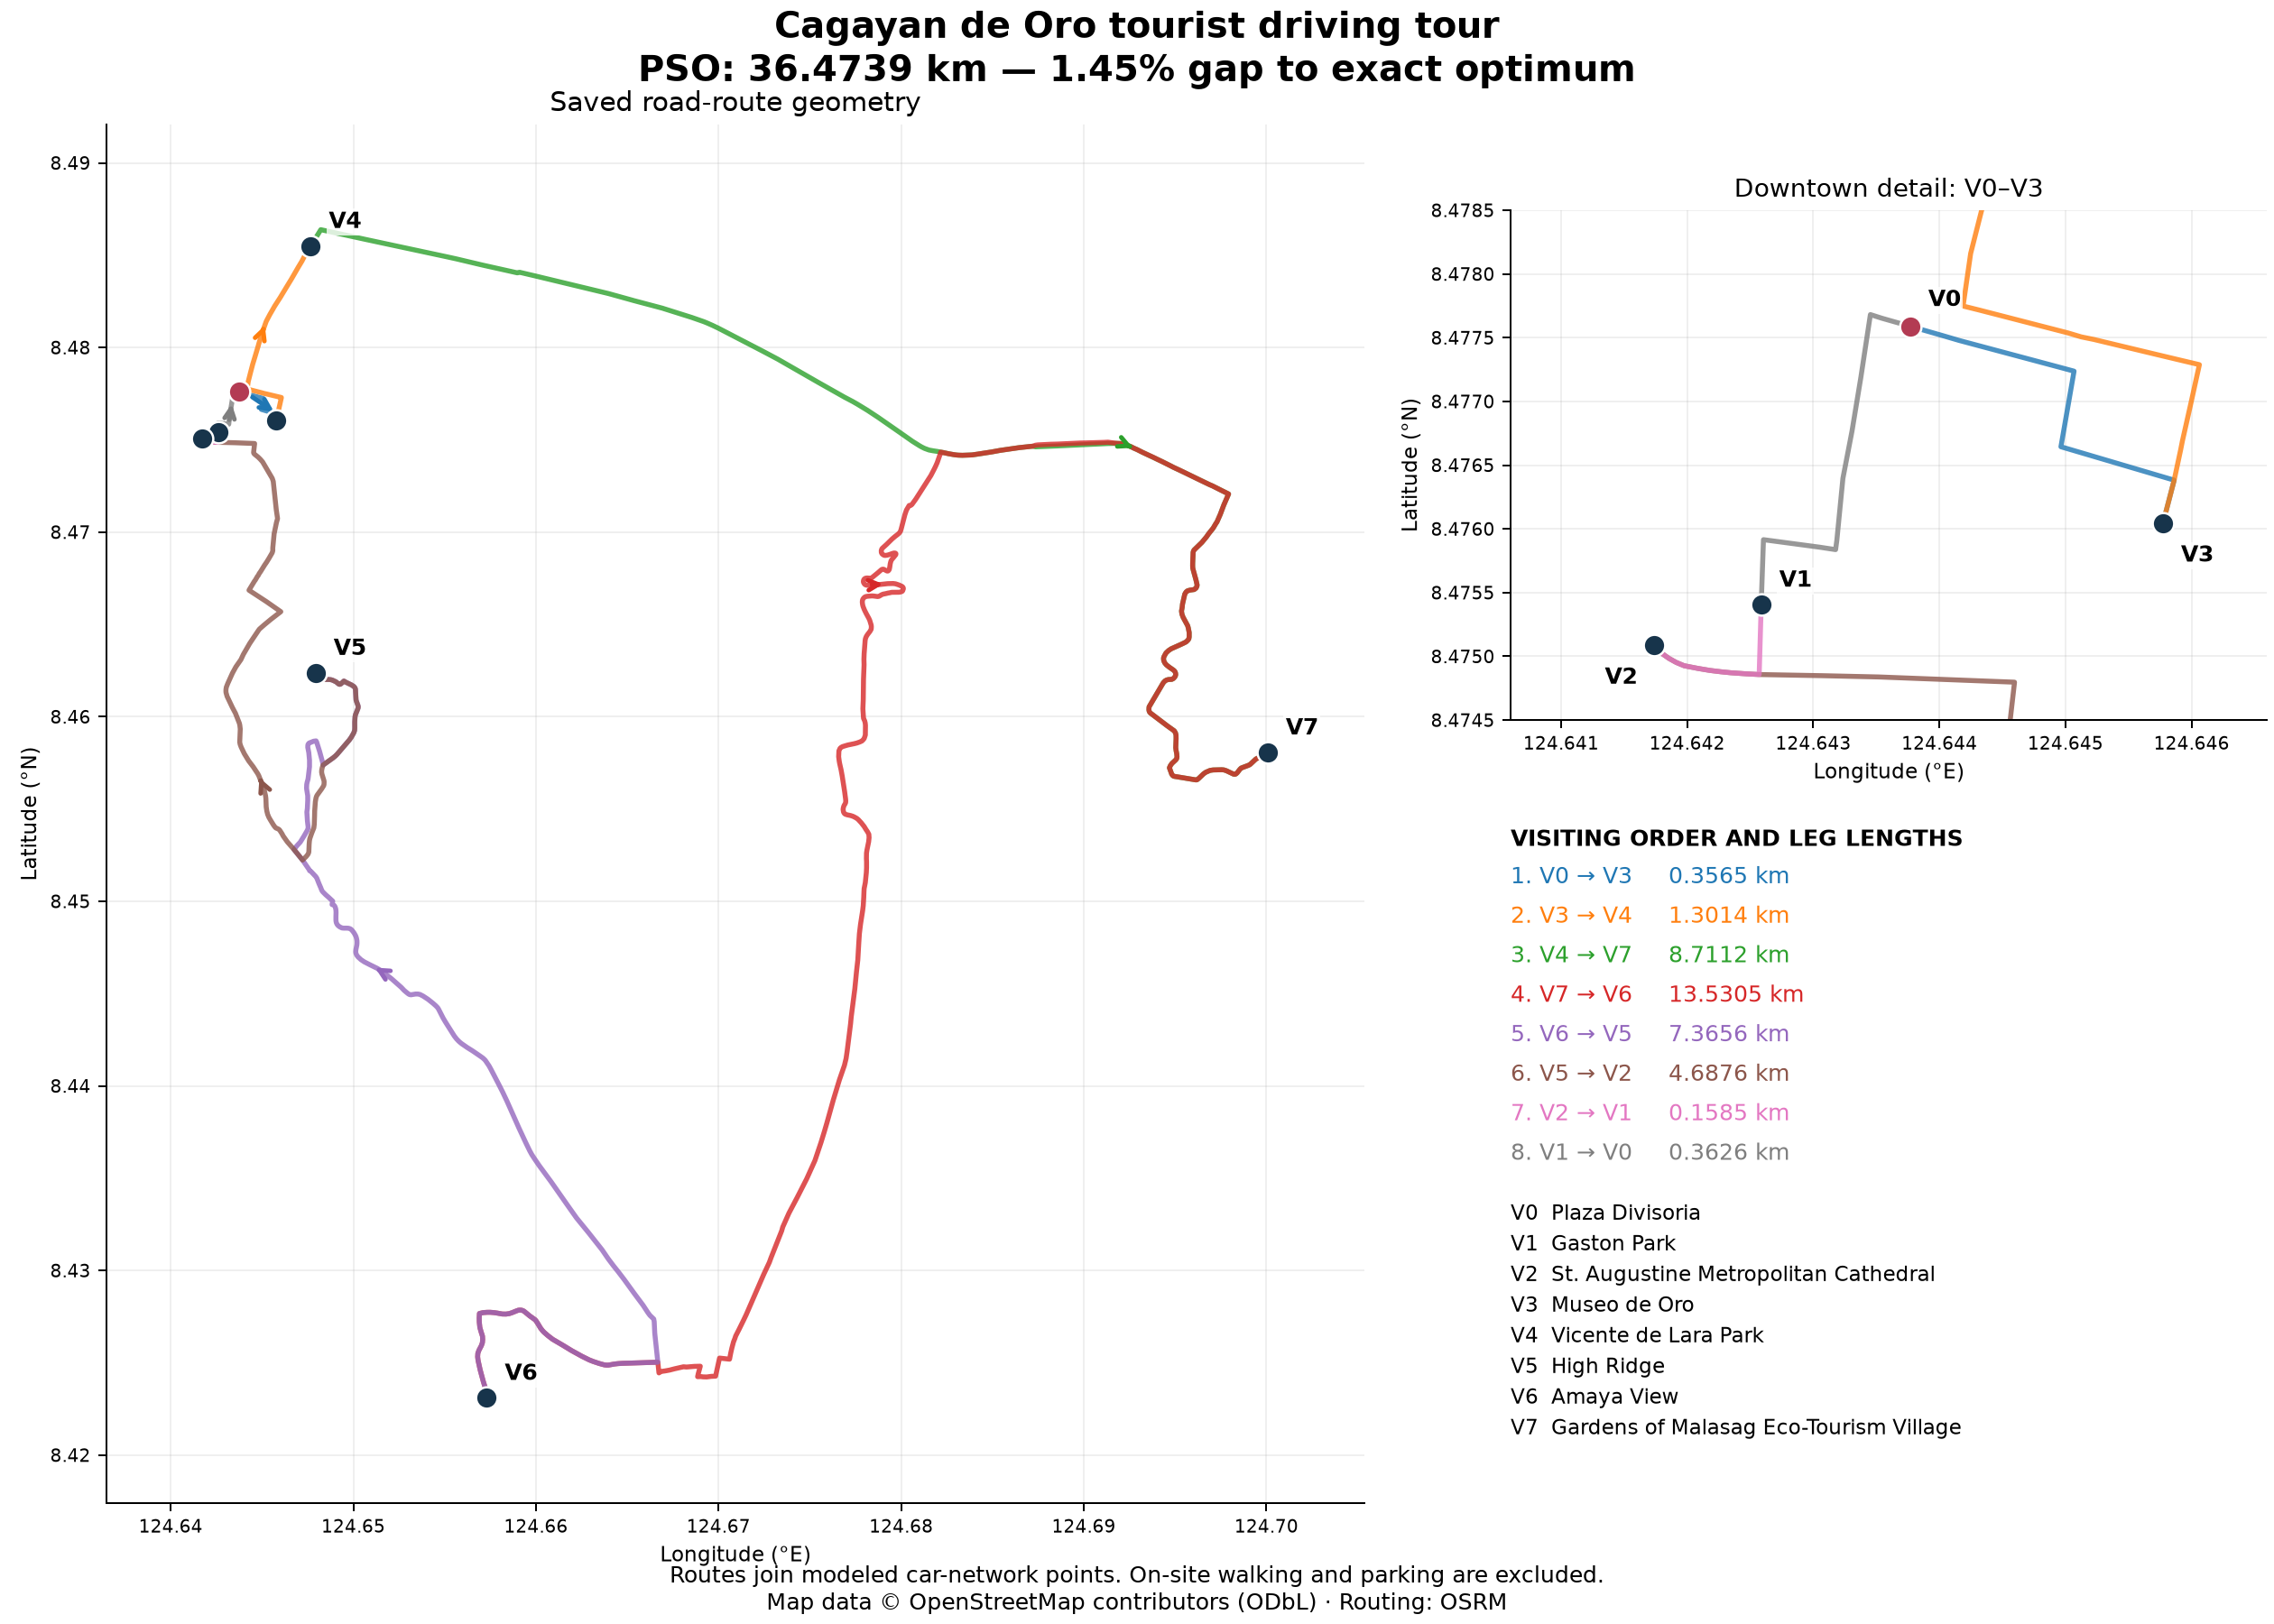

In [5]:
generate_visualizations(locations, matrix, summary, history, ROOT, output)
from IPython.display import Image, display
for filename in ["figure1_cdo_graph_network.png", "figure2_pso_convergence.png", "figure3_cdo_tour.png"]:
    display(Image(filename=str(output / filename), width=900))


## Interpretation and limits

Matching brute force proves optimality only for the saved eight-node cost matrix. OSRM selects recommended/fastest car routes; their lengths are not necessarily shortest-distance road paths. No claim is made that this is the shortest possible physical driving tour, a feasible one-day schedule, or a field-verified itinerary. Repeated seeds assess stochastic variation on this single instance, not scalability.

See `data/README.md` for provenance and access-point decisions. The original delivery project is preserved in `archive/delivery-example-c44f835.zip`.
